In [1]:

# STEP 1: Install the required libraries

!pip -q install pandas numpy matplotlib scipy openpyxl python-pptx

print("All required libraries are installed successfully!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 472.8/472.8 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 13.1 MB/s eta 0:00:00
All required libraries are installed successfully!


In [2]:

# STEP 2: Upload the Excel dataset

from google.colab import files
import os

uploaded = files.upload()

excel_files = [
    name for name in uploaded.keys()
    if name.lower().endswith((".xlsx", ".xls"))
]

if len(excel_files) == 0:
    raise ValueError(
        "No Excel file found. Upload your ApexPlanet .xlsx or .xls file."
    )

EXCEL_PATH = excel_files[0]

print("Dataset uploaded successfully!")
print("File name:", EXCEL_PATH)


Saving ApexPlanet_DataAnalytics_Dataset (5).xlsx to ApexPlanet_DataAnalytics_Dataset (5) (1).xlsx
Dataset uploaded successfully!
File name: ApexPlanet_DataAnalytics_Dataset (5) (1).xlsx


In [3]:

# STEP 3: Load and inspect the data

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

df = pd.read_excel(EXCEL_PATH, sheet_name="Sales_Dataset")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()


Dataset shape: (1000, 12)

Column names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']

First 5 rows:


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90



Missing values:


,Missing Values
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,0
Age,20
Gender,0
City,13
Product,0
Category,0
Quantity,0



Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB


In [4]:

# STEP 4: Clean the dataset

required_columns = [
    "Order_ID", "Order_Date", "Customer_ID", "Age",
    "Gender", "City", "Product", "Category",
    "Quantity", "Unit_Price", "Total_Sales"
]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

rows_before = len(df)
duplicates_before = int(df.duplicated().sum())

df = df.drop_duplicates().copy()

# Standardize text
text_columns = [
    "Order_ID", "Customer_ID", "Gender",
    "City", "Product", "Category"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Convert dates and numeric values
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

for col in ["Age", "Quantity", "Unit_Price", "Total_Sales"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Recalculate sales when quantity and price are valid
valid = (
    df["Quantity"].notna()
    & df["Unit_Price"].notna()
    & (df["Quantity"] >= 0)
    & (df["Unit_Price"] >= 0)
)

df.loc[valid, "Total_Sales"] = (
    df.loc[valid, "Quantity"] * df.loc[valid, "Unit_Price"]
)

# Remove rows missing essential fields
essential = [
    "Order_ID", "Order_Date", "Customer_ID",
    "Category", "Quantity", "Unit_Price", "Total_Sales"
]

df = df.dropna(subset=essential).copy()
df = df[df["Total_Sales"] >= 0].copy()

# Fill missing descriptive values
for col in ["Gender", "City", "Product", "Category"]:
    df[col] = df[col].fillna("Unknown").replace("", "Unknown")

# Add time features
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Year_Month"] = df["Order_Date"].dt.to_period("M").astype(str)

rows_after = len(df)

print("Cleaning completed!")
print("Original rows:", rows_before)
print("Exact duplicate rows found:", duplicates_before)
print("Rows after cleaning:", rows_after)
print("Rows removed overall:", rows_before - rows_after)

display(df.head())


Cleaning completed!
Original rows: 1000
Exact duplicate rows found: 0
Rows after cleaning: 1000
Rows removed overall: 0


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Year,Month,Year_Month
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,2025,2,2025-02
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80,2025,10,2025-10
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48,2025,5,2025-05
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,2025,12,2025-12
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,2025,11,2025-11


In [5]:

# STEP 5: Calculate KPIs and summaries

total_revenue = df["Total_Sales"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()

average_order_value = (
    total_revenue / total_orders if total_orders else 0
)

average_customer_spending = (
    total_revenue / total_customers if total_customers else 0
)

kpis = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Unique Orders",
        "Unique Customers",
        "Average Order Value",
        "Average Revenue per Customer"
    ],
    "Value": [
        total_revenue,
        total_orders,
        total_customers,
        average_order_value,
        average_customer_spending
    ]
})

monthly = (
    df.groupby("Year_Month", as_index=False)["Total_Sales"]
    .sum()
    .sort_values("Year_Month")
)

category_summary = (
    df.groupby("Category", as_index=False)
    .agg(
        Revenue=("Total_Sales", "sum"),
        Orders=("Order_ID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

city_summary = (
    df.groupby("City", as_index=False)
    .agg(
        Revenue=("Total_Sales", "sum"),
        Orders=("Order_ID", "nunique"),
        Customers=("Customer_ID", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

product_summary = (
    df.groupby("Product", as_index=False)
    .agg(
        Revenue=("Total_Sales", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

print("CORE KPIs")
display(kpis)

print("MONTHLY REVENUE")
display(monthly)

print("REVENUE BY CATEGORY")
display(category_summary)

print("REVENUE BY CITY")
display(city_summary)

print("TOP PRODUCTS")
display(product_summary.head(10))


CORE KPIs


,KPI,Value
0,Total Revenue,1.393994e+08
1,Unique Orders,9.920000e+02
2,Unique Customers,9.470000e+02
3,Average Order Value,1.405236e+05
4,Average Revenue per Customer,1.472011e+05


MONTHLY REVENUE


,Year_Month,Total_Sales
0,2025-01,10096190.73
1,2025-02,11511181.46
2,2025-03,13059899.94
3,2025-04,12222700.17
4,2025-05,10984689.25
5,2025-06,12912332.64
6,2025-07,11746226.80
7,2025-08,9448471.22
8,2025-09,9179896.29
9,2025-10,12500936.50


REVENUE BY CATEGORY


,Category,Revenue,Orders,Units_Sold
1,Electronics,50778581.70,353,1978
0,Education,25031689.40,177,977
4,Grocery,22231711.28,151,826
3,Furniture,21521561.48,158,855
2,Fashion,19835895.79,156,799


REVENUE BY CITY


,City,Revenue,Orders,Customers
6,Patna,19285966.89,135,134
4,Kolkata,18884349.57,132,132
0,Bengaluru,18773574.32,120,120
5,Mumbai,18757050.17,131,130
3,Hyderabad,17166766.87,125,125
1,Delhi,16097079.00,125,124
7,Pune,14513175.90,98,99
2,Gaya,14380859.39,117,117
8,Unknown,1540617.54,13,13


TOP PRODUCTS


,Product,Revenue,Units_Sold
2,Laptop,25443008.51,970
3,Mobile,25335573.19,1008
0,Book,25031689.40,977
4,Rice,22231711.28,826
1,Chair,21521561.48,855
5,Shoes,19835895.79,799


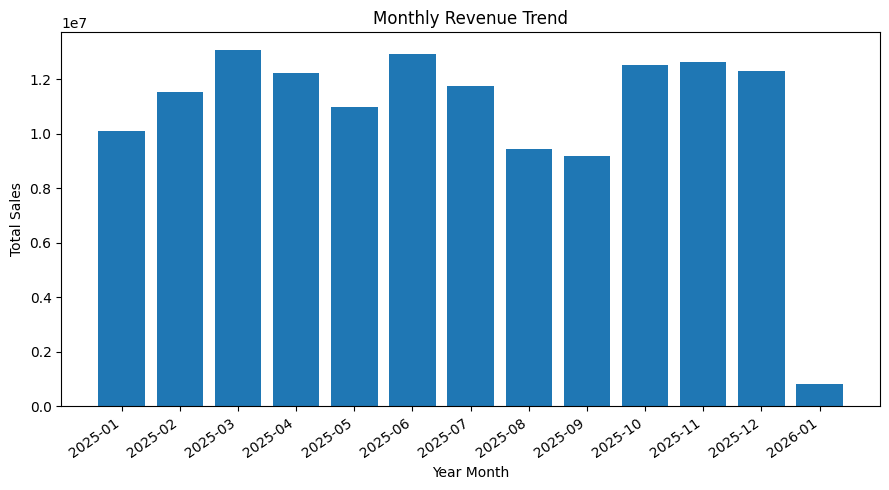

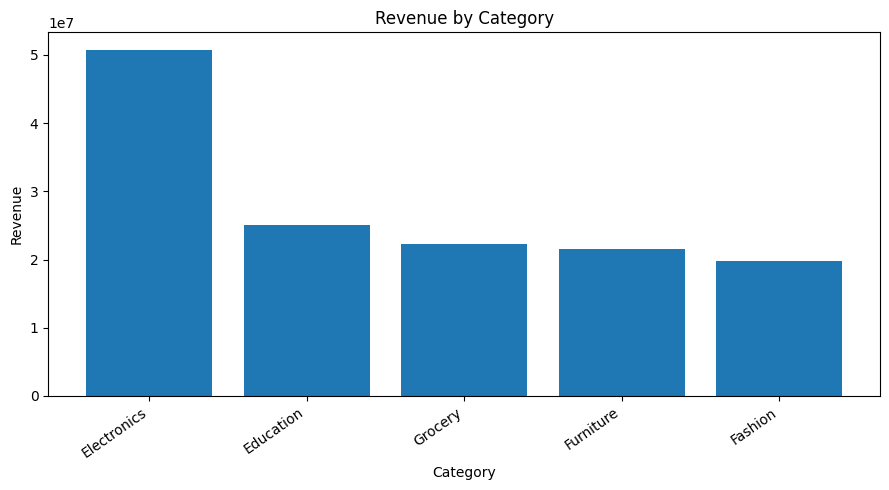

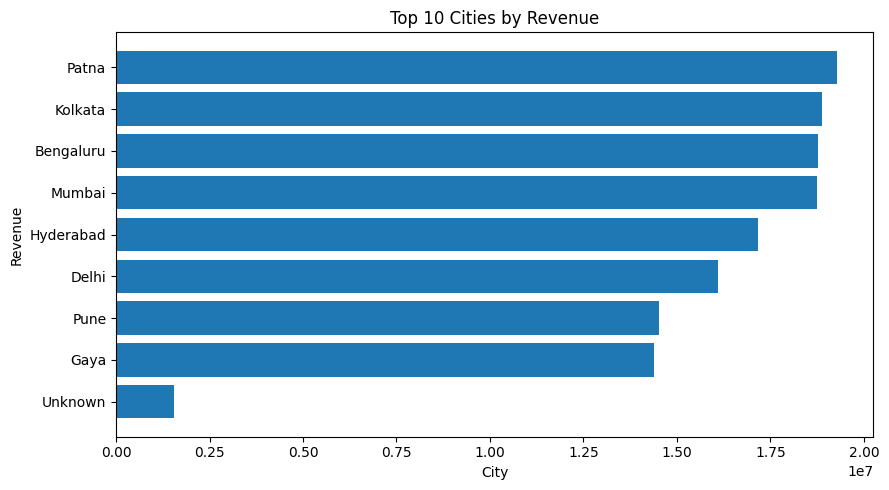

In [6]:

# STEP 6: Create portfolio charts

OUTPUT_DIR = "/content/Task5_Portfolio"
CHART_DIR = os.path.join(OUTPUT_DIR, "charts")

os.makedirs(CHART_DIR, exist_ok=True)

def save_bar_chart(data, x, y, title, filename, horizontal=False):
    plt.figure(figsize=(9, 5))

    if horizontal:
        plot_data = data.sort_values(y, ascending=True)
        plt.barh(plot_data[x].astype(str), plot_data[y])
    else:
        plt.bar(data[x].astype(str), data[y])
        plt.xticks(rotation=35, ha="right")

    plt.title(title)
    plt.xlabel(x.replace("_", " "))
    plt.ylabel(y.replace("_", " "))
    plt.tight_layout()

    path = os.path.join(CHART_DIR, filename)
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

    return path

monthly_chart = save_bar_chart(
    monthly, "Year_Month", "Total_Sales",
    "Monthly Revenue Trend", "monthly_revenue.png"
)

category_chart = save_bar_chart(
    category_summary, "Category", "Revenue",
    "Revenue by Category", "category_revenue.png"
)

city_chart = save_bar_chart(
    city_summary.head(10), "City", "Revenue",
    "Top 10 Cities by Revenue", "city_revenue.png",
    horizontal=True
)


,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,Segment
0,CUST1004,312,1,8321.54,1,1,1,At Risk / Inactive
1,CUST1017,261,1,264230.68,2,1,4,High Value / Occasional
2,CUST1026,95,1,164965.29,3,1,3,High Value / Occasional
3,CUST1032,249,1,146990.90,2,1,3,High Value / Occasional
4,CUST1038,241,1,37068.40,2,1,1,At Risk / Inactive


,Segment,Customers,Revenue
2,High Value / Occasional,223,50928724.16
0,At Risk / Inactive,363,42670700.80
3,Loyal / Active,241,39063528.38
1,Developing,120,6736486.31


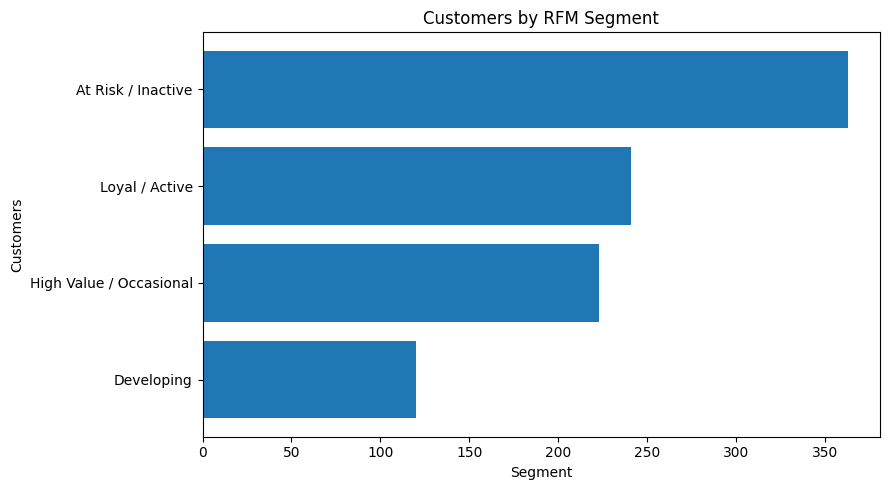

In [7]:

# STEP 7: Customer segmentation using RFM

reference_date = df["Order_Date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer_ID").agg(
    Recency=("Order_Date", lambda dates:
             (reference_date - dates.max()).days),
    Frequency=("Order_ID", "nunique"),
    Monetary=("Total_Sales", "sum")
).reset_index()

if len(rfm) >= 4:
    # Rank first to handle repeated values in the dataset
    rfm["R_Score"] = pd.qcut(
        rfm["Recency"].rank(method="first", ascending=False),
        4, labels=[1, 2, 3, 4]
    ).astype(int)

    rfm["F_Score"] = pd.qcut(
        rfm["Frequency"].rank(method="first"),
        4, labels=[1, 2, 3, 4]
    ).astype(int)

    rfm["M_Score"] = pd.qcut(
        rfm["Monetary"].rank(method="first"),
        4, labels=[1, 2, 3, 4]
    ).astype(int)

    def assign_segment(row):
        if row["R_Score"] >= 3 and row["F_Score"] >= 3:
            return "Loyal / Active"
        elif row["M_Score"] >= 3 and row["F_Score"] <= 2:
            return "High Value / Occasional"
        elif row["R_Score"] <= 2:
            return "At Risk / Inactive"
        else:
            return "Developing"

    rfm["Segment"] = rfm.apply(assign_segment, axis=1)
else:
    rfm["Segment"] = "Insufficient data for quartile scoring"

segment_summary = (
    rfm.groupby("Segment", as_index=False)
    .agg(
        Customers=("Customer_ID", "count"),
        Revenue=("Monetary", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

display(rfm.head())
display(segment_summary)

rfm_chart = save_bar_chart(
    segment_summary, "Segment", "Customers",
    "Customers by RFM Segment", "rfm_segments.png",
    horizontal=True
)


In [8]:

# STEP 8: Hypothesis testing

from scipy import stats

gender_data = df[["Customer_ID", "Gender", "Total_Sales"]].copy()
gender_data["Gender"] = (
    gender_data["Gender"].astype(str).str.strip().str.lower()
)

# Exclude customers whose gender label is inconsistent
gender_counts = gender_data.groupby("Customer_ID")["Gender"].nunique()
consistent_ids = gender_counts[gender_counts == 1].index

gender_data = gender_data[
    gender_data["Customer_ID"].isin(consistent_ids)
    & gender_data["Gender"].isin(["female", "male"])
]

# Aggregate spending to customer level
customer_spending = gender_data.groupby(
    ["Customer_ID", "Gender"], as_index=False
)["Total_Sales"].sum()

female = customer_spending.loc[
    customer_spending["Gender"] == "female", "Total_Sales"
].to_numpy()

male = customer_spending.loc[
    customer_spending["Gender"] == "male", "Total_Sales"
].to_numpy()

alpha = 0.05

print("H0: Female and male customers have equal mean spending.")
print("H1: Female and male customers have different mean spending.")
print("Significance level:", alpha)
print("Female customer count:", len(female))
print("Male customer count:", len(male))

if len(female) >= 2 and len(male) >= 2:
    test = stats.ttest_ind(female, male, equal_var=False)

    female_mean = float(np.mean(female))
    male_mean = float(np.mean(male))
    difference = female_mean - male_mean
    p_value = float(test.pvalue)

    # Welch confidence interval for the mean difference
    var_f = np.var(female, ddof=1)
    var_m = np.var(male, ddof=1)

    se = np.sqrt(var_f / len(female) + var_m / len(male))

    numerator = (var_f / len(female) + var_m / len(male)) ** 2
    denominator = (
        (var_f / len(female)) ** 2 / (len(female) - 1)
        + (var_m / len(male)) ** 2 / (len(male) - 1)
    )
    degrees_freedom = numerator / denominator

    critical_t = stats.t.ppf(0.975, degrees_freedom)

    ci_low = difference - critical_t * se
    ci_high = difference + critical_t * se

    if p_value < alpha:
        conclusion = (
            "Reject H0: evidence of a statistically significant "
            "difference in average spending."
        )
    else:
        conclusion = (
            "Fail to reject H0: insufficient evidence of a "
            "statistically significant difference in average spending."
        )

    print("\nFemale mean spending:", round(female_mean, 2))
    print("Male mean spending:", round(male_mean, 2))
    print("Female minus male mean:", round(difference, 2))
    print("t-statistic:", round(float(test.statistic), 4))
    print("p-value:", p_value)
    print("95% confidence interval:", (round(ci_low, 2), round(ci_high, 2)))
    print("Conclusion:", conclusion)

else:
    female_mean = male_mean = difference = np.nan
    p_value = ci_low = ci_high = np.nan
    conclusion = "Insufficient customer-level data for the test."
    print(conclusion)


H0: Female and male customers have equal mean spending.
H1: Female and male customers have different mean spending.
Significance level: 0.05
Female customer count: 445
Male customer count: 468

Female mean spending: 138779.51
Male mean spending: 143641.79
Female minus male mean: -4862.28
t-statistic: -0.6209
p-value: 0.5347965398224932
95% confidence interval: (np.float64(-20230.35), np.float64(10505.79))
Conclusion: Fail to reject H0: insufficient evidence of a statistically significant difference in average spending.


In [12]:

# STEP 9: Export the final Excel report

report_path = os.path.join(OUTPUT_DIR, "Capstone_Analysis_Report.xlsx")

kpi_table = kpis.copy()

hypothesis_summary = pd.DataFrame({
    "Metric": [
        "Business Question",
        "Null Hypothesis",
        "Alternative Hypothesis",
        "Test Used",
        "Significance Level",
        "Female Sample Size",
        "Male Sample Size",
        "Female Mean Spending",
        "Male Mean Spending",
        "Mean Difference (Female - Male)",
        "p-value",
        "95% CI Lower Bound",
        "95% CI Upper Bound",
        "Conclusion"
    ],
    "Value": [
        "Does average customer spending differ by gender?",
        "Female and male mean spending are equal.",
        "Female and male mean spending differ.",
        "Welch independent-samples t-test",
        alpha,
        len(female),
        len(male),
        female_mean,
        male_mean,
        difference,
        p_value,
        ci_low,
        ci_high,
        conclusion
    ]
})

data_quality = pd.DataFrame({
    "Metric": [
        "Original row count",
        "Exact duplicates initially found",
        "Rows after cleaning",
        "Rows removed overall"
    ],
    "Value": [
        rows_before,
        duplicates_before,
        rows_after,
        rows_before - rows_after
    ]
})

with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    kpi_table.to_excel(writer, sheet_name="KPIs", index=False)
    data_quality.to_excel(writer, sheet_name="Data_Quality", index=False)
    monthly.to_excel(writer, sheet_name="Monthly_Revenue", index=False)
    category_summary.to_excel(writer, sheet_name="Categories", index=False)
    city_summary.to_excel(writer, sheet_name="Cities", index=False)
    product_summary.to_excel(writer, sheet_name="Products", index=False)
    rfm.to_excel(writer, sheet_name="RFM_Customers", index=False)
    segment_summary.to_excel(writer, sheet_name="RFM_Segments", index=False)
    hypothesis_summary.to_excel(writer, sheet_name="Hypothesis_Test", index=False)

# Save cleaned dataset separately
cleaned_csv_path = os.path.join(OUTPUT_DIR, "Cleaned_Sales_Dataset.csv")
df.to_csv(cleaned_csv_path, index=False)

print("Excel report saved:", report_path)
print("Cleaned CSV saved:", cleaned_csv_path)


Excel report saved: /content/Task5_Portfolio/Capstone_Analysis_Report.xlsx
Cleaned CSV saved: /content/Task5_Portfolio/Cleaned_Sales_Dataset.csv


In [13]:

# Download Task 5 Portfolio ZIP file

from google.colab import files
import os
import zipfile

OUTPUT_DIR = "/content/Task5_Portfolio"
ZIP_PATH = "/content/BhavanaV_Task5_Portfolio.zip"

# Check that the portfolio folder exists
if not os.path.isdir(OUTPUT_DIR):
    raise FileNotFoundError(
        "Portfolio folder not found. Run your previous Task 5 code first."
    )

# Create the ZIP file
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, filenames in os.walk(OUTPUT_DIR):
        for filename in filenames:
            file_path = os.path.join(root, filename)
            arcname = os.path.relpath(file_path, OUTPUT_DIR)
            zipf.write(file_path, arcname)

print("ZIP file created successfully!")
print("File size:", round(os.path.getsize(ZIP_PATH) / 1024, 2), "KB")

# Download to your computer
files.download(ZIP_PATH)


ZIP file created successfully!
File size: 375.19 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>